# 🤖 Tarea 1 – Parte 2: del LLM al clasificador

**Flujo:** split estratificado (test aislado) → baseline zero-shot → supervisión débil con LLM (Qwen local) + auditoría humana → fine-tuning de DistilBERT multilingüe → evaluación final en test → comparativa.

**Etiquetas usadas**
- `categoria` = etiqueta editorial (sección del medio mapeada en la Parte 1). Se usa como **verdad de referencia** en validación y test.
- `etiqueta_llm` = etiqueta débil generada por el LLM. Se usa para **entrenar** el Transformer (supervisión débil).

> Recomendado: ejecutar en **Google Colab con GPU T4** (Entorno de ejecución → Cambiar tipo → T4 GPU). También corre en CPU, más lento.

In [1]:
import os, sys, json, time, shutil, random
EN_COLAB = "google.colab" in sys.modules
os.makedirs("datos", exist_ok=True); os.makedirs("modelo", exist_ok=True)
if EN_COLAB and not os.path.exists("datos/noticias.csv"):
    from google.colab import files
    print("Sube datos/noticias.csv (generado en 01_recoleccion.ipynb)")
    up = files.upload()
    for k in up:
        shutil.move(k, "datos/noticias.csv")

In [2]:
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt, seaborn as sns
from datetime import datetime
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from IPython.display import display
import transformers
from transformers import (pipeline, AutoTokenizer, AutoModelForSequenceClassification,
                          AutoModelForCausalLM, TrainingArguments, Trainer, set_seed)

SEED = 42
set_seed(SEED); random.seed(SEED); np.random.seed(SEED)
DEVICE = 0 if torch.cuda.is_available() else -1
print("transformers", transformers.__version__, "| torch", torch.__version__,
      "| GPU:", torch.cuda.get_device_name(0) if DEVICE == 0 else "no (CPU)")

ETIQUETAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]
L2I = {l: i for i, l in enumerate(ETIQUETAS)}
df = pd.read_csv("datos/noticias.csv")
df["titular"] = df["titular"].astype(str)
df["bajada"] = df["bajada"].fillna("").astype(str)
print(df.shape); df["categoria"].value_counts()

c:\Users\Lory\Documents\GitHub\tareas-python\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


transformers 5.20.1 | torch 2.14.1+cpu | GPU: no (CPU)
(394, 7)


categoria
politica              126
deportes               96
ciencia_tecnologia     87
economia               85
Name: count, dtype: int64

## 1. Partición 70 / 15 / 15 estratificada (`random_state=42`)
Se hace **al inicio** para que el conjunto de test quede aislado desde el principio: ningún paso de ajuste (prompt, hiperparámetros, selección de época) lo usa. Solo se abre en la sección 5.

In [3]:
idx = np.arange(len(df))
idx_train, idx_tmp = train_test_split(idx, test_size=0.30, stratify=df["categoria"], random_state=SEED)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.50, stratify=df.loc[idx_tmp, "categoria"], random_state=SEED)
df["split"] = "train"; df.loc[idx_val, "split"] = "val"; df.loc[idx_test, "split"] = "test"
assert not set(idx_train) & set(idx_test) and not set(idx_val) & set(idx_test)
display(pd.crosstab(df["categoria"], df["split"], margins=True))
print((df["split"].value_counts(normalize=True) * 100).round(1))

split,test,train,val,All
categoria,,,,
ciencia_tecnologia,13,61,13,87
deportes,15,67,14,96
economia,13,59,13,85
politica,19,88,19,126
All,60,275,59,394


split
train    69.8
test     15.2
val      15.0
Name: proportion, dtype: float64


## 2. Línea base Zero-Shot (sin fine-tuning) – 40 titulares
Modelo: `Recognai/bert-base-spanish-wwm-cased-xnli` (NLI en español). Se toman **40 titulares (10 por categoría) de train+val**, para no tocar el test. Este puntaje es el **piso** a superar.

In [8]:
ZS_MODEL = "Recognai/bert-base-spanish-wwm-cased-xnli"
zs = pipeline("zero-shot-classification", model=ZS_MODEL, device=DEVICE)
ZS_LABELS = {"política": "politica", "economía": "economia", "deportes": "deportes",
             "ciencia y tecnología": "ciencia_tecnologia"}
PLANTILLA = "Esta noticia trata sobre {}."

def zero_shot(textos):
    out = zs(list(textos), candidate_labels=list(ZS_LABELS), hypothesis_template=PLANTILLA)
    out = out if isinstance(out, list) else [out]
    return [ZS_LABELS[o["labels"][0]] for o in out], [o["scores"][0] for o in out]

pool = df[df["split"] != "test"]
n_cat = min(10, pool["categoria"].value_counts().min())
base40 = pool.groupby("categoria").sample(n=n_cat, random_state=SEED)
base40 = pd.concat([base40, pool.drop(base40.index).sample(40 - len(base40), random_state=SEED)]) if len(base40) < 40 else base40
t0 = time.time()
base40["pred_zs"], base40["score_zs"] = zero_shot(base40["titular"])
lat_zs = (time.time() - t0) / len(base40) * 1000
acc_zs40 = accuracy_score(base40["categoria"], base40["pred_zs"])
f1_zs40 = f1_score(base40["categoria"], base40["pred_zs"], average="macro", labels=ETIQUETAS)
print(f"ZERO-SHOT (40 titulares) → Accuracy = {acc_zs40:.3f} | F1 macro = {f1_zs40:.3f} | {lat_zs:.0f} ms/titular")
display(base40[["titular", "categoria", "pred_zs", "score_zs"]].head(10))

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 2654.84it/s]


ZERO-SHOT (40 titulares) → Accuracy = 0.525 | F1 macro = 0.414 | 326 ms/titular


,titular,categoria,pred_zs,score_zs
47,En 1993 se liberaron 300 bisontes en una prade...,ciencia_tecnologia,politica,0.325539
190,Trump llama a Musk un “tesoro nacional” tras c...,ciencia_tecnologia,politica,0.365954
135,La IA podría causar “incidentes graves” en uno...,ciencia_tecnologia,deportes,0.326477
43,Una resistencia olvidada frenó la expansión de...,ciencia_tecnologia,politica,0.462957
149,Ventas de ‘smartphones’ registran una caída de...,ciencia_tecnologia,economia,0.493215
202,Un Motorola razr 70 diferente: así es el teléf...,ciencia_tecnologia,deportes,0.565217
53,La Antártida se encuentra cubierta de hielo de...,ciencia_tecnologia,deportes,0.341604
155,El Niño en Perú: no está operativo ninguno de ...,ciencia_tecnologia,politica,0.320553
128,Fenómeno El Niño Costero: ¿cuáles pueden ser l...,ciencia_tecnologia,deportes,0.632393
181,Por qué China considera una amenaza la IA que ...,ciencia_tecnologia,politica,0.637731


## 3. Supervisión débil con LLM local (Qwen2.5-Instruct)
- Modelo: `Qwen/Qwen2.5-1.5B-Instruct` con GPU (o `Qwen2.5-0.5B-Instruct` en CPU). Corre local: **sin claves API** en el repositorio.
- **Prompt estructurado**: rol + definición de cada categoría + formato de respuesta de un solo dígito.
- **Confianza**: en vez de pedirle al LLM que “invente” un número, se toma la probabilidad que el modelo asigna a cada respuesta posible (softmax sobre los logits de los tokens `1`–`4`).

In [9]:
LLM_ID = "Qwen/Qwen2.5-1.5B-Instruct" if DEVICE == 0 else "Qwen/Qwen2.5-0.5B-Instruct"
tok_llm = AutoTokenizer.from_pretrained(LLM_ID)
tok_llm.padding_side = "left"
llm = AutoModelForCausalLM.from_pretrained(
    LLM_ID, torch_dtype=torch.float16 if DEVICE == 0 else torch.float32).to("cuda" if DEVICE == 0 else "cpu").eval()

SISTEMA = """Eres un editor de un diario peruano. Clasificas noticias en UNA de estas 4 categorías:
1 = politica: gobierno, Congreso, partidos, elecciones, ministros, justicia y fiscalía vinculadas a políticos.
2 = economia: mercados, empresas, empleo, precios, impuestos, MEF/BCRP, minería y comercio, finanzas personales.
3 = deportes: fútbol, selección, clubes, atletas, torneos y resultados deportivos.
4 = ciencia_tecnologia: ciencia, salud científica, espacio, tecnología, internet, apps, videojuegos, inteligencia artificial.
Responde SOLO con el dígito de la categoría (1, 2, 3 o 4)."""

def prompt(titular, bajada):
    msgs = [{"role": "system", "content": SISTEMA},
            {"role": "user", "content": f"Titular: {titular}\nBajada: {bajada[:300]}\nCategoría:"}]
    return tok_llm.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

ID_DIG = [tok_llm.encode(str(d), add_special_tokens=False)[0] for d in range(1, 5)]

@torch.no_grad()
def etiquetar_llm(titulares, bajadas, bs=16):
    etiquetas, confs = [], []
    for i in range(0, len(titulares), bs):
        lote = [prompt(t, b) for t, b in zip(titulares[i:i+bs], bajadas[i:i+bs])]
        enc = tok_llm(lote, return_tensors="pt", padding=True).to(llm.device)
        logits = llm(**enc).logits[:, -1, ID_DIG].float()
        p = torch.softmax(logits, dim=-1).cpu().numpy()
        etiquetas += [ETIQUETAS[k] for k in p.argmax(1)]
        confs += p.max(1).round(4).tolist()
    return etiquetas, confs

t0 = time.time()
df["etiqueta_llm"], df["confianza"] = etiquetar_llm(df["titular"].tolist(), df["bajada"].tolist())
lat_llm = (time.time() - t0) / len(df) * 1000
print(f"Etiquetadas {len(df)} noticias en {time.time()-t0:.0f} s ({lat_llm:.0f} ms/noticia)")

etq = df[["titular", "etiqueta_llm", "confianza"]].copy()
etq["modelo_llm"] = LLM_ID
etq["fecha"] = datetime.now().strftime("%Y-%m-%d")
etq["url"] = df["url"]
etq.to_csv("datos/etiquetas_llm.csv", index=False, encoding="utf-8")
display(etq.head()); print(etq["etiqueta_llm"].value_counts())

c:\Users\Lory\Documents\GitHub\tareas-python\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Lory\.cache\huggingface\hub\models--Qwen--Qwen2.5-0.5B-Instruct. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|█████

Etiquetadas 394 noticias en 1036 s (2629 ms/noticia)


,titular,etiqueta_llm,confianza,modelo_llm,fecha,url
0,Carlos Infante: “La matanza de Uchuraccay es u...,ciencia_tecnologia,0.5258,Qwen/Qwen2.5-0.5B-Instruct,2026-10-18,https://larepublica.pe/politica/2026/08/15/car...
1,"Jorge Nieto a Álvaro Vargas Llosa: ""Su rol de ...",deportes,0.3879,Qwen/Qwen2.5-0.5B-Instruct,2026-10-18,https://larepublica.pe/politica/2026/10/18/jor...
2,Comisión de Ética recomienda suspender por 120...,deportes,0.3461,Qwen/Qwen2.5-0.5B-Instruct,2026-10-18,https://larepublica.pe/politica/2026/10/18/com...
3,Keiko Fujimori coordinó con Delcy Rodríguez la...,deportes,0.4158,Qwen/Qwen2.5-0.5B-Instruct,2026-10-18,https://larepublica.pe/politica/2026/10/18/kei...
4,Detención de seis policías por presunto robo r...,ciencia_tecnologia,0.5792,Qwen/Qwen2.5-0.5B-Instruct,2026-10-18,https://larepublica.pe/politica/2026/10/18/det...


etiqueta_llm
ciencia_tecnologia    234
deportes              111
politica               48
economia                1
Name: count, dtype: int64


### 3.1 Auditoría humana de 20 predicciones al azar
Revisar cada fila leyendo **titular + bajada** y marcar en `REVISION_HUMANA` con `1` si la etiqueta del LLM es correcta y `0` si no (en el mismo orden de la tabla). Luego volver a ejecutar esta celda y la siguiente.

In [10]:
audit = df.sample(20, random_state=SEED)[["titular", "bajada", "etiqueta_llm", "confianza", "categoria"]]
audit = audit.reset_index(drop=True)
with pd.option_context("display.max_colwidth", 160):
    display(audit[["titular", "bajada", "etiqueta_llm", "confianza"]])

,titular,bajada,etiqueta_llm,confianza
0,Comisión del Senado suspende sesión “hasta nuevo aviso” tras ausencia de legisladores de izquierda,"La Comisión de Constitución del Senado, que preside Carlos Mesía (Fuerza Popular) debate y votar este jueves el nuevo predictamen sobre el pedido del Gobier...",deportes,0.3361
1,Norway–Peru Investment Forum 2026 reunirá a empresas líderes para impulsar nuevas oportunidades de inversión entre Noruega y el Perú,,ciencia_tecnologia,0.7175
2,Gobierno transfiere más de S/19 millones a gobiernos regionales para cumplir con beneficios laborales en el sector Educación,El Gobierno autorizó la transferencia de recursos que superan los S/19 millones a favor de diversos gobiernos regionales para financiar el pago de beneficio...,ciencia_tecnologia,0.3268
3,El voto 31: Este es el escenario que muestra el peso de Obras para el fujimorismo en la delegación de facultades,Los cinco senadores del partido de Ricardo Belmont serán piezas clave si es que se insiste con la modificación del texto de delegación de facultades recibid...,ciencia_tecnologia,0.5027
4,Resultados ONPE en San Borja al 99.526 %: sigue aquí el conteo oficial de las Elecciones Regionales y Municipales 2026,,ciencia_tecnologia,0.5792
5,Precio del dólar en Perú: cierre del domingo 18 de octubre,"Precio del dólar hoy EN VIVO: cotización en compra y venta del dólar en el Perú en la jornada de hoy, domingo 18 de octubre. Revisa los movimientos de la mo...",deportes,0.4836
6,"Partidos de hoy, sábado 17 de octubre: horarios y canales para ver fútbol EN VIVO","Conoce EN VIVO la programación de este sábado, horarios y canales de TV de todos los enfrentamientos en el Torneo Clausura de la Liga 1 y en los distintos c...",deportes,0.4971
7,"EE.UU. busca sostener su liderazgo turístico pese al retroceso de visitantes, ¿cómo planea lograrlo el gobierno de Trump?",El enviado presidencial de Donald Trump sostuvo en la cumbre del WTTC que Estados Unidos busca mantener su posición como principal economía turística mundia...,deportes,0.3938
8,"Netflix despedirá a unos 1.000 empleados, el 6 % de su plantilla, según medios","Este recorte afectará a los departamentos de producto, tecnología, asuntos legales y recursos humanos. La medida se debería a la necesidad de priorizar recu...",deportes,0.3927
9,Keiko Fujimori sobre facultades: “Esperemos que el debate se retome con la prioridad y la urgencia que el país necesita”,La presidenta Keiko Fujimori dijo esperar que el debate sobre la delegación de facultades solicitada por el Ejecutivo en el Senado se retome “con la priorid...,ciencia_tecnologia,0.5120


In [11]:
# ✍️ Completar tras la lectura manual (1 = acuerdo, 0 = desacuerdo), 20 valores:
REVISION_HUMANA = [None] * 20

if None in REVISION_HUMANA:
    print("⚠️ Auditoría manual pendiente: se muestra provisionalmente el acuerdo con la sección editorial.")
    REVISION = (audit["etiqueta_llm"] == audit["categoria"]).astype(int).tolist()
    TIPO_AUDIT = "provisional (vs. sección editorial)"
else:
    REVISION = REVISION_HUMANA
    TIPO_AUDIT = "humana"
audit["acuerdo"] = REVISION
acuerdo = int(sum(REVISION))
print(f"Acuerdo LLM–Humano ({TIPO_AUDIT}): {acuerdo}/20 = {acuerdo/20:.0%}")
audit.to_csv("datos/auditoria_20.csv", index=False)
display(audit[audit["acuerdo"] == 0][["titular", "etiqueta_llm", "categoria"]])

⚠️ Auditoría manual pendiente: se muestra provisionalmente el acuerdo con la sección editorial.
Acuerdo LLM–Humano (provisional (vs. sección editorial)): 2/20 = 10%


,titular,etiqueta_llm,categoria
0,Comisión del Senado suspende sesión “hasta nue...,deportes,politica
1,Norway–Peru Investment Forum 2026 reunirá a em...,ciencia_tecnologia,economia
2,Gobierno transfiere más de S/19 millones a gob...,ciencia_tecnologia,economia
3,El voto 31: Este es el escenario que muestra e...,ciencia_tecnologia,politica
4,Resultados ONPE en San Borja al 99.526 %: sigu...,ciencia_tecnologia,politica
5,Precio del dólar en Perú: cierre del domingo 1...,deportes,economia
7,EE.UU. busca sostener su liderazgo turístico p...,deportes,economia
8,"Netflix despedirá a unos 1.000 empleados, el 6...",deportes,ciencia_tecnologia
9,Keiko Fujimori sobre facultades: “Esperemos qu...,ciencia_tecnologia,politica
10,Número de regiones que irán a reelección aumen...,ciencia_tecnologia,politica


In [12]:
# Acuerdo global LLM vs. sección editorial en train+val (referencia; el test se reserva)
tv = df[df.split != "test"]
print(f"Acuerdo LLM vs sección (train+val): {(tv.etiqueta_llm == tv.categoria).mean():.1%}")
display(pd.crosstab(tv["categoria"], tv["etiqueta_llm"], rownames=["sección"], colnames=["LLM"]))

Acuerdo LLM vs sección (train+val): 17.4%


LLM,ciencia_tecnologia,deportes,economia,politica
sección,,,,
ciencia_tecnologia,27,39,0,8
deportes,69,8,0,4
economia,47,21,0,4
politica,59,24,1,23


## 4. Fine-tuning de `distilbert-base-multilingual-cased`
- Entrena con **titular** y la **etiqueta débil del LLM** (`etiqueta_llm`) del conjunto train.
- Valida por época contra la etiqueta editorial de val; se conserva la mejor época según **F1 macro**.
- Config.: 5 épocas, batch 16, lr 5e-5, `max_length=64` (los titulares son cortos, ver EDA).

In [14]:
FT_MODEL = "distilbert-base-multilingual-cased"
COL_ENTRENAMIENTO = "etiqueta_llm"   # cambiar a "categoria" para entrenar con la etiqueta editorial
tok = AutoTokenizer.from_pretrained(FT_MODEL)

class DS(torch.utils.data.Dataset):
    def __init__(self, textos, etiquetas):
        self.enc = tok(list(textos), truncation=True, max_length=64, padding="max_length")
        self.y = [L2I[e] for e in etiquetas]
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        item = {k: torch.tensor(v[i]) for k, v in self.enc.items()}
        item["labels"] = torch.tensor(self.y[i]); return item

tr, va, te = df[df.split == "train"], df[df.split == "val"], df[df.split == "test"]
ds_tr = DS(tr["titular"], tr[COL_ENTRENAMIENTO])
ds_va = DS(va["titular"], va["categoria"])

def compute_metrics(p):
    pred = np.argmax(p.predictions, axis=1)
    return {"accuracy": accuracy_score(p.label_ids, pred),
            "f1_macro": f1_score(p.label_ids, pred, average="macro")}

modelo = AutoModelForSequenceClassification.from_pretrained(
    FT_MODEL, num_labels=4, id2label=dict(enumerate(ETIQUETAS)), label2id=L2I)

args = TrainingArguments(
    output_dir="modelo", num_train_epochs=5, per_device_train_batch_size=16, per_device_eval_batch_size=32,
    learning_rate=5e-5, weight_decay=0.01,
    eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
    load_best_model_at_end=True, metric_for_best_model="f1_macro", greater_is_better=True,
    logging_strategy="epoch", report_to="none", seed=SEED)
trainer = Trainer(model=modelo, args=args, train_dataset=ds_tr, eval_dataset=ds_va, compute_metrics=compute_metrics)
t0 = time.time(); trainer.train(); print(f"Entrenamiento: {time.time()-t0:.0f} s")

hist = pd.DataFrame([h for h in trainer.state.log_history if "eval_f1_macro" in h])[["epoch", "eval_loss", "eval_accuracy", "eval_f1_macro"]]
display(hist.round(4))

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 1716.90it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
c:\Users\Lory\Documents\GitHub\tareas-python\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,1.029437,2.114353,0.220339,0.090278
2,0.787875,2.705751,0.118644,0.058333
3,0.586153,3.013842,0.067797,0.040816
4,0.402193,3.169620,0.000000,0.000000
5,0.342929,3.290627,0.067797,0.040816


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.11it/s]
c:\Users\Lory\Documents\GitHub\tareas-python\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.29it/s]
c:\Users\Lory\Documents\GitHub\tareas-python\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.68it/s]
c:\Users\Lory\Documents\GitHub\tareas-python\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████| 1

Entrenamiento: 318 s


,epoch,eval_loss,eval_accuracy,eval_f1_macro
0,1.0,2.1144,0.2203,0.0903
1,2.0,2.7058,0.1186,0.0583
2,3.0,3.0138,0.0678,0.0408
3,4.0,3.1696,0.0000,0.0000
4,5.0,3.2906,0.0678,0.0408


In [15]:
trainer.save_model("modelo"); tok.save_pretrained("modelo")
for d in os.listdir("modelo"):
    if d.startswith("checkpoint-"): shutil.rmtree(os.path.join("modelo", d))
print(sorted(os.listdir("modelo")))

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.54it/s]

['.gitkeep', 'config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json', 'training_args.bin']


## 5. Evaluación final en el conjunto de TEST reservado

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 1100.19it/s]


TEST (n=60) → Accuracy = 0.217 | F1 macro = 0.089

                    precision    recall  f1-score   support

          politica      0.000     0.000     0.000        19
          economia      0.000     0.000     0.000        13
          deportes      0.000     0.000     0.000        15
ciencia_tecnologia      0.217     1.000     0.356        13

          accuracy                          0.217        60
         macro avg      0.054     0.250     0.089        60
      weighted avg      0.047     0.217     0.077        60



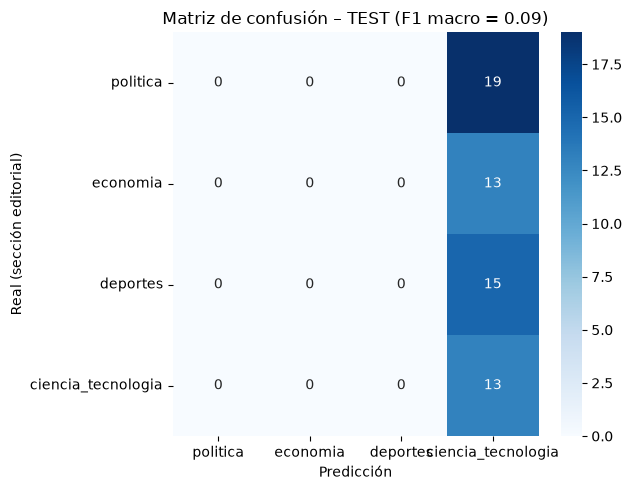

In [16]:
clf = pipeline("text-classification", model="modelo", tokenizer="modelo", device=DEVICE, top_k=None)

def pred_ft(textos):
    out = clf(list(textos), truncation=True, max_length=64, batch_size=32)
    return [max(o, key=lambda d: d["score"])["label"] for o in out]

t0 = time.time(); te_pred = pred_ft(te["titular"]); lat_ft = (time.time() - t0) / len(te) * 1000
y_te = te["categoria"].tolist()
acc_ft = accuracy_score(y_te, te_pred); f1_ft = f1_score(y_te, te_pred, average="macro", labels=ETIQUETAS)
print(f"TEST (n={len(te)}) → Accuracy = {acc_ft:.3f} | F1 macro = {f1_ft:.3f}\n")
rep = classification_report(y_te, te_pred, labels=ETIQUETAS, digits=3, output_dict=True, zero_division=0)
print(classification_report(y_te, te_pred, labels=ETIQUETAS, digits=3, zero_division=0))

cm = confusion_matrix(y_te, te_pred, labels=ETIQUETAS)
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=ETIQUETAS, yticklabels=ETIQUETAS, ax=ax)
ax.set_xlabel("Predicción"); ax.set_ylabel("Real (sección editorial)")
ax.set_title(f"Matriz de confusión – TEST (F1 macro = {f1_ft:.2f})")
plt.tight_layout(); plt.savefig("modelo/matriz_confusion_test.png", dpi=130); plt.show()

In [18]:
f1_cat = {c: rep[c]["f1-score"] for c in ETIQUETAS}
mejor, peor = max(f1_cat, key=f1_cat.get), min(f1_cat, key=f1_cat.get)
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
r, c = np.unravel_index(cm_off.argmax(), cm_off.shape)
print("F1 por categoría:", {k: round(v, 3) for k, v in f1_cat.items()})
print(f"Mejor: {mejor} ({f1_cat[mejor]:.2f}) | Peor: {peor} ({f1_cat[peor]:.2f})")
print(f"Confusión más frecuente: real '{ETIQUETAS[r]}' → predicho '{ETIQUETAS[c]}' ({cm_off.max()} casos)")
errores = te.assign(pred=te_pred)[lambda d: d.pred != d.categoria][["titular", "categoria", "pred"]]
display(errores.head(10))

F1 por categoría: {'politica': 0.0, 'economia': 0.0, 'deportes': 0.0, 'ciencia_tecnologia': 0.356}
Mejor: ciencia_tecnologia (0.36) | Peor: politica (0.00)
Confusión más frecuente: real 'politica' → predicho 'ciencia_tecnologia' (19 casos)


,titular,categoria,pred
2,Comisión de Ética recomienda suspender por 120...,politica,ciencia_tecnologia
7,Jorge Nieto plantea aprobar las 20 facultades ...,politica,ciencia_tecnologia
13,Comisión de Constitución aún no convoca a sesi...,politica,ciencia_tecnologia
23,"Precio del dólar hoy en Perú, domingo 18 de oc...",economia,ciencia_tecnologia
24,"Petroperú mejora sus resultados financieros, p...",economia,ciencia_tecnologia
25,"Gobierno destina S/12,4 millones a Defensa par...",economia,ciencia_tecnologia
29,UTC jugará la Liga 2 en 2027: es el primer des...,deportes,ciencia_tecnologia
33,¡Trujillo se pintó de crema! Universitario ven...,deportes,ciencia_tecnologia
35,Sporting Cristal se mantiene como líder del To...,deportes,ciencia_tecnologia
36,Pablo Guede expone el preocupante estado de Es...,deportes,ciencia_tecnologia


### Reflexión por categoría
*(Interpretar junto con la salida de la celda anterior.)*

- **deportes** suele ser la categoría más fácil: su vocabulario es muy exclusivo (*Alianza Lima, Universitario, Liga 1, gol, selección, Gareca/Fossati, ATP*) y casi no se comparte con otras secciones.
- **politica ↔ economia** es la frontera más difusa: titulares sobre el MEF, el presupuesto, impuestos, el Congreso aprobando leyes laborales o mineras usan léxico de ambas. El medio decide la sección por el *ángulo* de la nota, algo que el titular solo no siempre revela.
- **ciencia_tecnologia** tiende a ser la peor: es la clase con menos ejemplos y mezcla temas heterogéneos (salud, espacio, apps, videojuegos, IA, empresas tecnológicas). Las notas sobre empresas tech o criptomonedas se confunden con economía, y las de inteligencia artificial en el Estado, con política.
- Como el modelo se entrena con **etiquetas débiles del LLM**, los desacuerdos LLM–sección (vistos en la auditoría) se trasladan como ruido al Transformer, sobre todo en las fronteras anteriores.

## 6. Comparativa en el mismo TEST: Zero-shot vs. LLM débil vs. Transformer fine-tuned

In [19]:
# Zero-shot sobre el test completo (solo inferencia)
t0 = time.time(); zs_te, _ = zero_shot(te["titular"]); lat_zs_te = (time.time() - t0) / len(te) * 1000
# LLM débil sobre el test (sus etiquetas ya existen)
llm_te = te["etiqueta_llm"].tolist()

# Extra ligero: TF-IDF + Regresión logística (mismas etiquetas débiles) → usado como respaldo en la app
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
import joblib
tfidf = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=1, sublinear_tf=True, strip_accents="unicode", lowercase=True),
                      LogisticRegression(max_iter=2000, C=5, class_weight="balanced"))
tfidf.fit(pd.concat([tr["titular"], va["titular"]]), pd.concat([tr[COL_ENTRENAMIENTO], va["categoria"]]))
t0 = time.time(); tf_te = tfidf.predict(te["titular"]); lat_tf = (time.time() - t0) / len(te) * 1000
joblib.dump(tfidf, "modelo/tfidf_logreg.joblib")

def fila(nombre, pred, lat, params, costo):
    return {"modelo": nombre, "accuracy_test": accuracy_score(y_te, pred),
            "f1_macro_test": f1_score(y_te, pred, average="macro", labels=ETIQUETAS),
            "latencia_ms_titular": lat, "parametros": params, "costo": costo}

comp = pd.DataFrame([
    fila(f"Zero-shot ({ZS_MODEL.split('/')[-1]})", zs_te, lat_zs_te, "110 M", "Sin entrenamiento; 4 pasadas NLI por titular"),
    fila(f"LLM débil ({LLM_ID.split('/')[-1]})", llm_te, lat_llm, LLM_ID.split("-")[-2], "GPU recomendada; prompt largo"),
    fila("DistilBERT multilingüe fine-tuned", te_pred, lat_ft, "135 M", "Entrenamiento ~1–3 min en T4; 1 pasada"),
    fila("TF-IDF + LogReg (extra)", tf_te, lat_tf, "<1 M", "CPU, milisegundos"),
])
comp["mejora_vs_zeroshot"] = comp["f1_macro_test"] - comp.loc[0, "f1_macro_test"]
display(comp.round(3))
print(f"Piso zero-shot (40 titulares): F1 macro = {f1_zs40:.3f}")

,modelo,accuracy_test,f1_macro_test,latencia_ms_titular,parametros,costo,mejora_vs_zeroshot
0,Zero-shot (bert-base-spanish-wwm-cased-xnli),0.683,0.622,357.852,110 M,Sin entrenamiento; 4 pasadas NLI por titular,0.000
1,LLM débil (Qwen2.5-0.5B-Instruct),0.217,0.189,2628.956,0.5B,GPU recomendada; prompt largo,-0.433
2,DistilBERT multilingüe fine-tuned,0.217,0.089,34.170,135 M,Entrenamiento ~1–3 min en T4; 1 pasada,-0.533
3,TF-IDF + LogReg (extra),0.317,0.301,1.540,<1 M,"CPU, milisegundos",-0.321


Piso zero-shot (40 titulares): F1 macro = 0.414


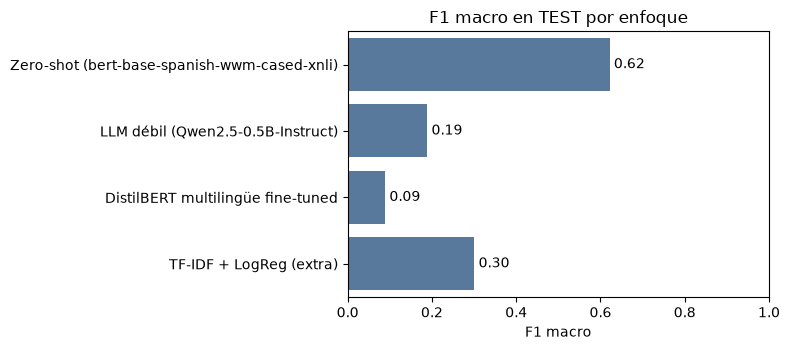

In [20]:
fig, ax = plt.subplots(figsize=(8, 3.6))
sns.barplot(data=comp, y="modelo", x="f1_macro_test", ax=ax, color="#4C78A8")
for i, v in enumerate(comp["f1_macro_test"]): ax.text(v + 0.01, i, f"{v:.2f}", va="center")
ax.set_xlim(0, 1); ax.set_title("F1 macro en TEST por enfoque"); ax.set_xlabel("F1 macro"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig("modelo/comparativa_f1.png", dpi=130); plt.show()

### Decisión para un entorno real
Criterios: **precisión (F1 macro)**, **costo computacional** y **latencia**.

- El **zero-shot** no requiere datos, pero es el más lento por titular (una inferencia NLI por cada categoría candidata) y el menos preciso: sirve solo como piso.
- El **LLM** entiende mejor el contexto (usa titular + bajada) pero requiere GPU y cientos de MB de memoria por consulta; su rol ideal es **etiquetar datos** (offline), no servir en producción.
- El **DistilBERT fine-tuned** destila el conocimiento del LLM en un modelo de una sola pasada, que corre en CPU en pocos ms por titular.

**Elección:** el Transformer fine-tuned para producción (mejor equilibrio precisión/latencia/costo), con el LLM reservado para etiquetar nuevos lotes y re-entrenar periódicamente. Si el despliegue es muy restringido (p. ej. Streamlit Cloud gratuito, sin espacio para un modelo de ~500 MB), el TF-IDF + LogReg es un respaldo aceptable. *(Contrastar con la tabla: si en tu ejecución el orden de F1 cambia, ajusta esta conclusión.)*

In [21]:
metricas = {
    "fecha_evaluacion": datetime.now().strftime("%Y-%m-%d %H:%M"),
    "n_total": int(len(df)), "n_train": int(len(tr)), "n_val": int(len(va)), "n_test": int(len(te)),
    "f1_macro_test": round(f1_ft, 4), "accuracy_test": round(acc_ft, 4),
    "f1_zeroshot_40": round(f1_zs40, 4), "accuracy_zeroshot_40": round(acc_zs40, 4),
    "acuerdo_llm_humano": acuerdo, "acuerdo_llm_humano_pct": acuerdo / 20, "tipo_auditoria": TIPO_AUDIT,
    "modelo_ft": FT_MODEL, "modelo_llm": LLM_ID, "modelo_zeroshot": ZS_MODEL,
    "f1_por_categoria": {k: round(v, 4) for k, v in f1_cat.items()},
    "comparativa": comp.round(4).to_dict(orient="records"),
}
json.dump(metricas, open("modelo/metricas.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
df[["titular", "categoria", "etiqueta_llm", "split"]].to_csv("modelo/split.csv", index=False)
print(f"Resultados Test: F1 Macro: {f1_ft:.2f} | Zero-shot: {f1_zs40:.2f} | Acuerdo LLM-Humano: {acuerdo}/20")

Resultados Test: F1 Macro: 0.09 | Zero-shot: 0.41 | Acuerdo LLM-Humano: 2/20


In [22]:
# Solo en Colab: descargar los resultados para copiarlos a la carpeta tarea_1/ del repo
if EN_COLAB:
    from google.colab import files
    shutil.make_archive("modelo_y_datos", "zip", root_dir=".", base_dir="modelo")
    shutil.make_archive("datos_parte2", "zip", root_dir=".", base_dir="datos")
    files.download("modelo_y_datos.zip"); files.download("datos_parte2.zip")